In [4]:
import numpy as np
import pandas as pd

# Load Dataset
df = pd.read_csv('Nassau Candy Distributor.csv')

# Calculate KPIs
df['Gross Margin (%)'] = (df['Gross Profit'] / df['Sales']) * 100
df['Profit per Unit'] = df['Gross Profit'] / df['Units']

print("Data Loaded Successfully!")
df.head()

Data Loaded Successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Gross Margin (%),Profit per Unit
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,64.923077,2.11
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,65.333333,2.45
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,71.346705,2.49
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,69.444444,2.50
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,65.333333,2.45


--- Division Summary ---
    Division  Total_Sales  Total_Profit  Avg_Margin
0  Chocolate    131692.90      88824.62   67.458162
1      Other      9663.25       4333.45   37.672457
2      Sugar       427.48        284.73   57.689001

--- Top 5 Profitable Products ---
                                   Total_Sales  Total_Profit  Avg_Margin
Product Name                                                            
Wonka Bar -Scrumdiddlyumptious        27874.80      19357.50   69.444444
Wonka Bar - Triple Dazzle Caramel     28485.00      18610.20   65.333333
Wonka Bar - Milk Chocolate            26867.75      17443.37   64.923077
Wonka Bar - Nutty Crunch Surprise     23574.95      16819.95   71.346705
Wonka Bar - Fudge Mallows             24890.40      16593.60   66.666667


C:\Users\singh\AppData\Local\Temp\ipykernel_22804\3804860357.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=div_summary, x="Division", y="Total_Profit", palette="magma")


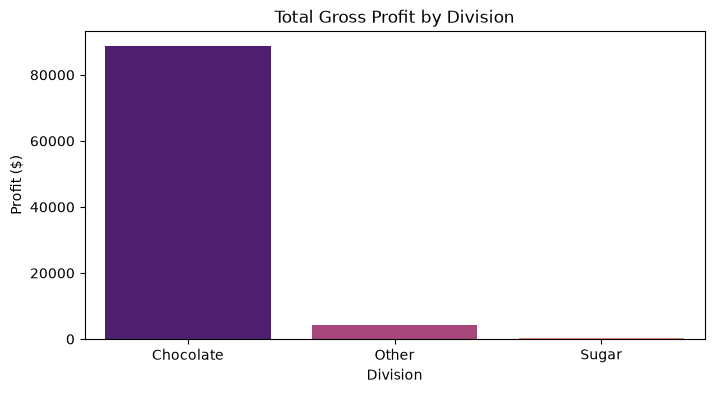

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Dataset Load Karein
df = pd.read_csv("Nassau Candy Distributor.csv")

# 2. Key Metrics Calculation
df["Gross Margin (%)"] = (df["Gross Profit"] / df["Sales"]) * 100
df["Profit per Unit"] = df["Gross Profit"] / df["Units"]

# 3. Division-wise Performance
div_summary = (
    df.groupby("Division")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Avg_Margin=("Gross Margin (%)", "mean"),
    )
    .reset_index()
)
print("--- Division Summary ---")
print(div_summary)

# 4. Product Level Analysis (Top vs Bottom Products)
prod_summary = (
    df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Avg_Margin=("Gross Margin (%)", "mean"),
    )
    .sort_values(by="Total_Profit", ascending=False)
)
print("\n--- Top 5 Profitable Products ---")
print(prod_summary.head(5))

# 5. Visualizations
plt.figure(figsize=(8, 4))
sns.barplot(data=div_summary, x="Division", y="Total_Profit", palette="magma")
plt.title("Total Gross Profit by Division")
plt.ylabel("Profit ($)")
plt.show()